# Milestone 4: Testing Our One Change (fine-tuning the top of InceptionV3)

**Baseline (Milestone 2):** Kermany et al. (Cell 2018). ImageNet InceptionV3 is kept **fully frozen**; only a new linear layer is trained.

**Hypothesis (Milestone 3, written in `milestone3/hypothesis.md` *before* this code existed):**
> Unfreezing the **last two Inception blocks** (`Mixed_7b`, `Mixed_7c`) and fine-tuning them at a small learning rate (1e-4) will raise **AUC by about 1-2 points**. **Specificity** will improve the most, and sensitivity will stay within about 1 point.

**What changes and what stays identical**

| | Baseline | Our change |
|---|---|---|
| Trainable part | new linear layer only | last 2 Inception blocks + new linear layer |
| Learning rate | 1e-3 (Adam) | linear layer 1e-3 (unchanged); unfrozen blocks **1e-4** |
| Data, split, 299×299 input, batch 256, 4000 steps, test set | same | same |

**Ablation:** unfreeze **0** (baseline), **1**, **2** blocks, and the **whole network**.

**Speed trick:** the frozen lower part of the network never changes, so we run it **once** and cache its output (the same idea as the paper's "bottleneck" cache). Then we only train the small top part.

In [1]:
import os, json, random, time
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import torchvision, matplotlib.pyplot as plt
from torchvision import datasets, transforms
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
DATA_DIR = "data/chest_xray"
os.makedirs("results", exist_ok=True)
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


## 1. Load the images once (resized to 299×299, grayscale, same preprocessing as Milestone 2)

In [2]:
gray_tfm = transforms.Compose([transforms.Resize((299, 299)), transforms.Grayscale(1), transforms.PILToTensor()])

def load_split(split):
    cache = f"results/imgs_{split}.pt"
    if os.path.exists(cache):
        return torch.load(cache)
    ds = datasets.ImageFolder(f"{DATA_DIR}/{split}", transform=gray_tfm)
    xs, ys = [], []
    for x, y in torch.utils.data.DataLoader(ds, batch_size=128, num_workers=4):
        xs.append(x); ys.append(y)
    out = (torch.cat(xs), torch.cat(ys), ds.classes, [p for p, _ in ds.samples])
    torch.save(out, cache)
    return out

t0 = time.time()
img_train, y_train, CLASSES, _ = load_split("train")
img_test, y_test, _, test_paths = load_split("test")
print(f"train {tuple(img_train.shape)}  test {tuple(img_test.shape)}  classes {CLASSES}  ({time.time() - t0:.0f}s)")

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
def to_input(u8):                      # uint8 grayscale -> normalised 3-channel float (as in Milestone 2)
    x = u8.to(device).float().div(255).expand(-1, 3, -1, -1)
    return (x - MEAN) / STD

train (5232, 1, 299, 299)  test (624, 1, 299, 299)  classes ['NORMAL', 'PNEUMONIA']  (56s)


## 2. Split the network into a frozen part and a trainable part
InceptionV3's layers run in this order. "Unfreeze k blocks" means the last *k* of them are trained, and everything before them is frozen and cached.

In [3]:
LAYERS = ["Conv2d_1a_3x3", "Conv2d_2a_3x3", "Conv2d_2b_3x3", "maxpool1", "Conv2d_3b_1x1", "Conv2d_4a_3x3",
          "maxpool2", "Mixed_5b", "Mixed_5c", "Mixed_5d", "Mixed_6a", "Mixed_6b", "Mixed_6c", "Mixed_6d",
          "Mixed_6e", "Mixed_7a", "Mixed_7b", "Mixed_7c"]

def load_inception():
    net = torchvision.models.inception_v3(weights="IMAGENET1K_V1")
    net.fc = nn.Identity(); net.aux_logits = False; net.AuxLogits = None
    return net.to(device)

class Top(nn.Module):
    # Trainable part: last k Inception blocks (pretrained weights) + global average pool + new linear layer
    def __init__(self, net, k):
        super().__init__()
        self.blocks = nn.Sequential(*[getattr(net, n) for n in LAYERS[len(LAYERS) - k:]]) if k else nn.Identity()
        self.fc = nn.Linear(2048, 2)
        nn.init.normal_(self.fc.weight, std=0.001); nn.init.zeros_(self.fc.bias)   # as in the paper's code
    def forward(self, x):
        x = self.blocks(x.float())
        if x.dim() == 4:
            x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc(x)

@torch.no_grad()
def frozen_features(net, imgs, k, bs=64):
    # Run the frozen first part once; cache its output in float16 to save memory
    net.eval(); out = []
    for i in range(0, len(imgs), bs):
        x = net._transform_input(to_input(imgs[i:i + bs]))
        for n in LAYERS[:len(LAYERS) - k]:
            x = getattr(net, n)(x)
        if k == 0:
            x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        out.append(x.half())
    return torch.cat(out)

KS = [0, 1, 2]
net = load_inception()
t0 = time.time()
FEATS = {k: (frozen_features(net, img_train, k), frozen_features(net, img_test, k)) for k in KS}
for k in KS:
    print(f"k={k}: cached input to trainable part has shape {tuple(FEATS[k][0].shape[1:])}")
print(f"({time.time() - t0:.0f}s)")
del net

k=0: cached input to trainable part has shape (2048,)
k=1: cached input to trainable part has shape (2048, 8, 8)
k=2: cached input to trainable part has shape (1280, 8, 8)
(56s)


## 3. Training and evaluation (same protocol as Milestone 2)

In [4]:
STEPS, BATCH = int(os.environ.get("STEPS", 4000)), 256
LR_HEAD, LR_BLOCKS = 1e-3, 1e-4

def split_train_val(seed, n, val_frac=0.1):            # same 90/10 split as Milestone 2
    perm = torch.randperm(n, generator=torch.Generator().manual_seed(seed))
    n_val = int(val_frac * n)
    return perm[n_val:], perm[:n_val]

@torch.no_grad()
def predict(model, X, bs=256):
    model.eval()
    return torch.cat([F.softmax(model(X[i:i + bs]), 1)[:, 1] for i in range(0, len(X), bs)]).cpu().numpy()

def metrics(prob, y):
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"accuracy": 100 * (tp + tn) / len(y), "sensitivity": 100 * tp / (tp + fn),
            "specificity": 100 * tn / (tn + fp), "precision": 100 * tp / (tp + fp),
            "auc": 100 * roc_auc_score(y, prob), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

def run(k, seed):
    set_seed(seed)
    Xtr_all, Xte = FEATS[k]
    tr, va = split_train_val(seed, len(Xtr_all))
    Xtr, Ytr = Xtr_all[tr], y_train[tr].to(device)
    model = Top(load_inception(), k).to(device)
    groups = [{"params": model.fc.parameters(), "lr": LR_HEAD}]
    if k:
        groups.append({"params": model.blocks.parameters(), "lr": LR_BLOCKS})
    opt = torch.optim.Adam(groups)
    t0 = time.time()
    for step in range(1, STEPS + 1):
        model.train()
        idx = torch.randint(0, len(Xtr), (BATCH,), device=device)
        loss = F.cross_entropy(model(Xtr[idx]), Ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    train_acc = 100 * ((predict(model, Xtr) >= 0.5) == Ytr.cpu().numpy()).mean()
    val_acc = 100 * ((predict(model, Xtr_all[va]) >= 0.5) == y_train[va].numpy()).mean()
    prob = predict(model, Xte)
    m = metrics(prob, y_test.numpy()) | {"train_acc": train_acc, "val_acc": val_acc,
                                         "trainable_params": sum(p.numel() for p in model.parameters()),
                                         "minutes": (time.time() - t0) / 60}
    print(f"k={k} seed={seed}: test acc {m['accuracy']:.2f}  sens {m['sensitivity']:.2f}  spec {m['specificity']:.2f}  "
          f"AUC {m['auc']:.2f} | train acc {train_acc:.2f}  val acc {val_acc:.2f}  ({m['minutes']:.1f} min)")
    return m, prob

## 4. Ablation: unfreeze 0 / 1 / 2 blocks
k = 0 is the baseline from Milestone 2 (5 seeds). Fine-tuning is slower (about 16 min per run on a laptop GPU), so we use 2 seeds for our main change (2 blocks) and 1 seed for 1 block.

In [5]:
SEEDS = {0: [0, 1, 2, 3, 4], 1: [0], 2: [0, 1]}
RESULTS, PROBS = {}, {}
for k in KS:
    RESULTS[k] = []
    for s in SEEDS[k]:
        m, p = run(k, s)
        RESULTS[k].append(m)
        if s == 0:
            PROBS[k] = p
json.dump({str(k): v for k, v in RESULTS.items()}, open("results/ablation_blocks.json", "w"), indent=2)

k=0 seed=0: test acc 80.45  sens 97.95  spec 51.28  AUC 92.73 | train acc 99.60  val acc 98.66  (0.0 min)


k=0 seed=1: test acc 81.41  sens 98.46  spec 52.99  AUC 93.05 | train acc 99.66  val acc 97.13  (0.0 min)


k=0 seed=2: test acc 78.85  sens 98.97  spec 45.30  AUC 92.52 | train acc 99.75  val acc 95.98  (0.0 min)


k=0 seed=3: test acc 80.77  sens 98.21  spec 51.71  AUC 93.05 | train acc 99.68  val acc 97.32  (0.0 min)


k=0 seed=4: test acc 79.65  sens 99.23  spec 47.01  AUC 93.04 | train acc 99.68  val acc 96.18  (0.0 min)


k=1 seed=0: test acc 82.21  sens 99.74  spec 52.99  AUC 92.29 | train acc 100.00  val acc 98.85  (10.2 min)


k=2 seed=0: test acc 81.25  sens 99.23  spec 51.28  AUC 91.74 | train acc 100.00  val acc 98.66  (20.0 min)


k=2 seed=1: test acc 80.45  sens 99.74  spec 48.29  AUC 93.46 | train acc 100.00  val acc 99.04  (18.0 min)


## 5. Whole network fine-tuned (last ablation row)
Training *all* 22M parameters cannot use the cache: every step needs a full forward and backward pass on images, and 4000 steps of batch 256 would take hours on a laptop. So this row uses a **smaller budget** (batch 32, `FULL_STEPS` steps, every layer at lr 1e-4, head at 1e-3, 1 seed). Its number is a rough guide, not a like-for-like comparison.

In [6]:
FULL_STEPS, FULL_BATCH = int(os.environ.get("FULL_STEPS", 1000)), 32

def run_full(seed=0):
    set_seed(seed)
    tr, va = split_train_val(seed, len(img_train))
    X, Y = img_train[tr].to(device), y_train[tr].to(device)
    net = load_inception(); net.fc = nn.Linear(2048, 2).to(device)
    nn.init.normal_(net.fc.weight, std=0.001); nn.init.zeros_(net.fc.bias)
    body = [p for n, p in net.named_parameters() if not n.startswith("fc.")]
    opt = torch.optim.Adam([{"params": net.fc.parameters(), "lr": LR_HEAD}, {"params": body, "lr": LR_BLOCKS}])
    t0 = time.time()
    for step in range(1, FULL_STEPS + 1):
        net.train()
        idx = torch.randint(0, len(X), (FULL_BATCH,), device=device)
        loss = F.cross_entropy(net(to_input(X[idx])), Y[idx])
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 500 == 0:
            print(f"  step {step}/{FULL_STEPS}  loss {loss.item():.4f}  ({(time.time() - t0) / 60:.1f} min)")
    @torch.no_grad()
    def prob_of(imgs):
        net.eval()
        return torch.cat([F.softmax(net(to_input(imgs[i:i + 64])), 1)[:, 1] for i in range(0, len(imgs), 64)]).cpu().numpy()
    prob = prob_of(img_test)
    m = metrics(prob, y_test.numpy()) | {"train_acc": 100 * ((prob_of(img_train[tr]) >= 0.5) == y_train[tr].numpy()).mean(),
                                         "val_acc": 100 * ((prob_of(img_train[va]) >= 0.5) == y_train[va].numpy()).mean(),
                                         "trainable_params": sum(p.numel() for p in net.parameters()),
                                         "minutes": (time.time() - t0) / 60}
    print(f"whole network: test acc {m['accuracy']:.2f}  sens {m['sensitivity']:.2f}  spec {m['specificity']:.2f}  AUC {m['auc']:.2f}")
    return m, prob

RESULTS["all"], = [[run_full(0)[0]]]
json.dump({str(k): v for k, v in RESULTS.items()}, open("results/ablation_all.json", "w"), indent=2)

  step 500/1000  loss 0.0003  (3.6 min)


  step 1000/1000  loss 0.0290  (7.2 min)


whole network: test acc 78.37  sens 100.00  spec 42.31  AUC 93.93


## 6. Results

In [7]:
PAPER = {"accuracy": 92.8, "sensitivity": 93.2, "specificity": 90.1, "auc": 96.8}
NAMES = {0: "0 blocks (baseline)", 1: "1 block  (Mixed_7c)", 2: "2 blocks (Mixed_7b+7c)", "all": "whole network*"}
keys = ["accuracy", "sensitivity", "specificity", "precision", "auc"]
summary = {}
print(f"{'Unfrozen':<24}{'params':>9}" + "".join(f"{k[:11]:>15}" for k in keys) + f"{'train acc':>11}")
print(f"{'paper (frozen)':<24}{'':>9}" + "".join(f"{PAPER.get(k, float('nan')):>15.1f}" for k in keys))
for k, runs in RESULTS.items():
    mean = {m: np.mean([r[m] for r in runs]) for m in keys + ["train_acc"]}
    std  = {m: np.std([r[m] for r in runs]) for m in keys}
    summary[k] = (mean, std)
    print(f"{NAMES[k]:<24}{runs[0]['trainable_params'] / 1e6:>8.2f}M" +
          "".join(f"{mean[m]:>9.2f}±{std[m]:<5.2f}" for m in keys) + f"{mean['train_acc']:>11.2f}")
print("\n* smaller training budget, 1 seed (see Section 5)")

Unfrozen                   params       accuracy    sensitivity    specificity      precision            auc  train acc
paper (frozen)                              92.8           93.2           90.1            nan           96.8
0 blocks (baseline)         0.00M    80.22±0.89     98.56±0.48     49.66±2.97     76.56±0.98     92.88±0.22       99.67
1 block  (Mixed_7c)         6.08M    82.21±0.00     99.74±0.00     52.99±0.00     77.96±0.00     92.29±0.00      100.00
2 blocks (Mixed_7b+7c)     11.13M    80.85±0.40     99.49±0.26     49.79±1.50     76.76±0.49     92.60±0.86      100.00
whole network*             21.79M    78.37±0.00    100.00±0.00     42.31±0.00     74.29±0.00     93.93±0.00       99.94

* smaller training budget, 1 seed (see Section 5)


In [8]:
# Check the prediction we wrote down BEFORE running the experiment
b, f = summary[0][0], summary[2][0]
d = {m: f[m] - b[m] for m in ["auc", "specificity", "sensitivity", "accuracy"]}
print("Change from baseline (2 blocks unfrozen - frozen):")
for m, v in d.items():
    print(f"  {m:<12} {v:+.2f} points")
print()
checks = [("AUC rises by about 1-2 points",                 d["auc"] >= 0.5),
          ("specificity improves the most",                 d["specificity"] > 0 and d["specificity"] >= max(d["sensitivity"], d["auc"])),
          ("sensitivity stays within about 1 point",        abs(d["sensitivity"]) <= 1.5)]
for text, ok in checks:
    print(f"  [{'SUPPORTED' if ok else 'NOT supported'}] {text}")

Change from baseline (2 blocks unfrozen - frozen):
  auc          -0.27 points
  specificity  +0.13 points
  sensitivity  +0.92 points
  accuracy     +0.62 points

  [NOT supported] AUC rises by about 1-2 points
  [NOT supported] specificity improves the most
  [SUPPORTED] sensitivity stays within about 1 point


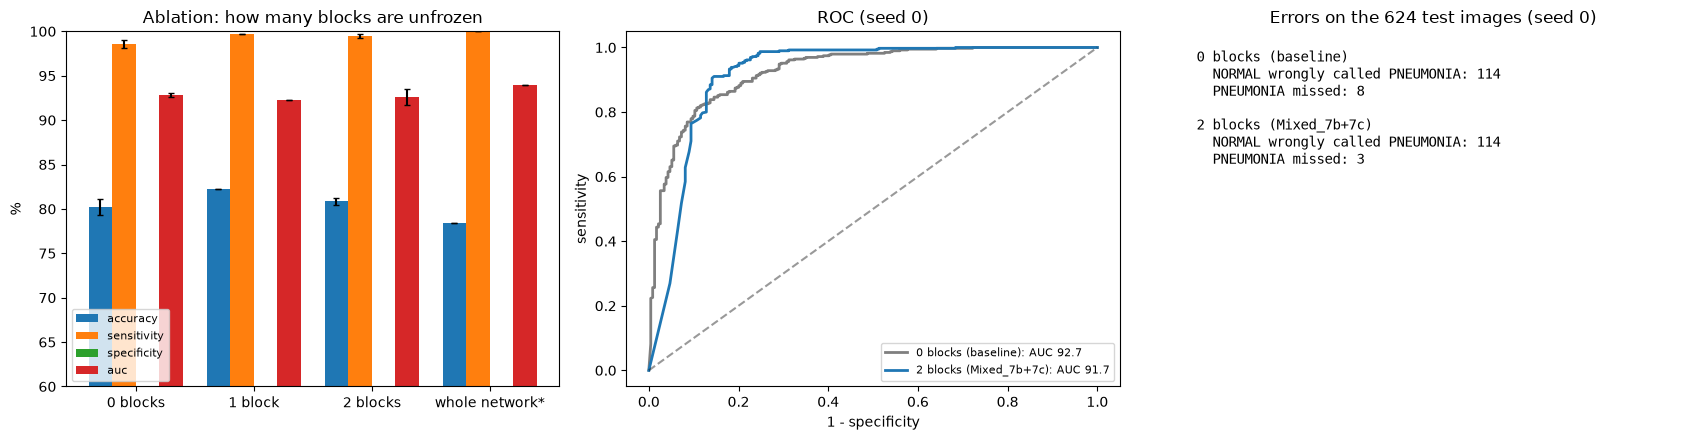

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
# (a) metrics per ablation setting
labels = [NAMES[k].split("(")[0].strip() for k in RESULTS]
x = np.arange(len(labels)); w = 0.2
for i, m in enumerate(["accuracy", "sensitivity", "specificity", "auc"]):
    axes[0].bar(x + (i - 1.5) * w, [summary[k][0][m] for k in RESULTS], w,
                yerr=[summary[k][1][m] for k in RESULTS], label=m, capsize=2)
axes[0].set_xticks(x, labels); axes[0].set_ylim(60, 100); axes[0].set_ylabel("%"); axes[0].legend(fontsize=8, loc="lower left")
axes[0].set_title("Ablation: how many blocks are unfrozen")
# (b) ROC: baseline vs 2 blocks
for k, c in [(0, "tab:gray"), (2, "tab:blue")]:
    fpr, tpr, _ = roc_curve(y_test.numpy(), PROBS[k])
    axes[1].plot(fpr, tpr, color=c, lw=2, label=f"{NAMES[k]}: AUC {roc_auc_score(y_test.numpy(), PROBS[k]) * 100:.1f}")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4); axes[1].legend(loc="lower right", fontsize=8)
axes[1].set_xlabel("1 - specificity"); axes[1].set_ylabel("sensitivity"); axes[1].set_title("ROC (seed 0)")
# (c) confusion matrices side by side
cm = lambda p: confusion_matrix(y_test.numpy(), (p >= 0.5).astype(int))
txt = ""
for k in (0, 2):
    (tn, fp), (fn, tp) = cm(PROBS[k])
    txt += f"{NAMES[k]}\n  NORMAL wrongly called PNEUMONIA: {fp}\n  PNEUMONIA missed: {fn}\n\n"
axes[2].text(0.02, 0.95, txt, va="top", family="monospace", fontsize=10); axes[2].axis("off")
axes[2].set_title("Errors on the 624 test images (seed 0)")
plt.tight_layout(); plt.savefig("results/ablation.png", dpi=150); plt.show()

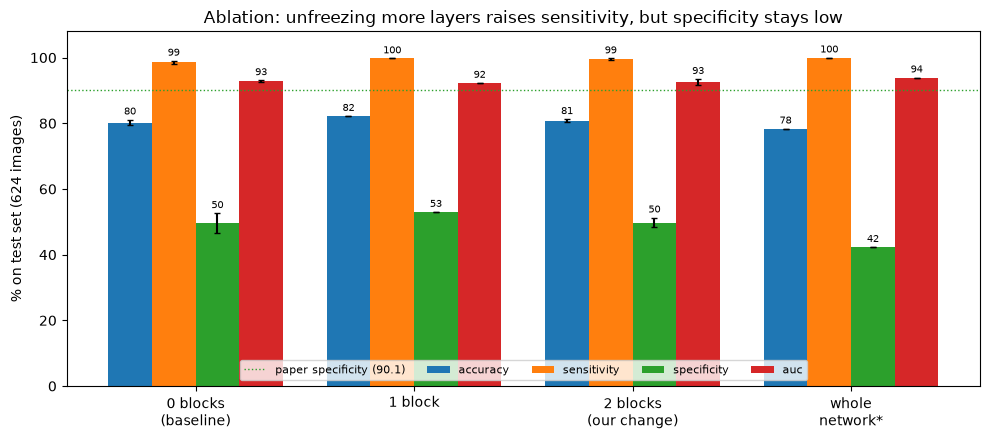

In [1]:
# Corrected bar chart: the y-axis above starts at 60 %, which hides the specificity bars (~40-53 %).
# Re-drawn from the saved results file with the full 0-100 % axis.
import json, numpy as np, matplotlib.pyplot as plt
R = json.load(open("results/ablation_all.json"))
labels = {"0": "0 blocks\n(baseline)", "1": "1 block", "2": "2 blocks\n(our change)", "all": "whole\nnetwork*"}
mets = ["accuracy", "sensitivity", "specificity", "auc"]
x, w = np.arange(len(R)), 0.2
plt.figure(figsize=(10, 4.5))
for i, m in enumerate(mets):
    mean = [np.mean([r[m] for r in R[k]]) for k in R]; std = [np.std([r[m] for r in R[k]]) for k in R]
    bars = plt.bar(x + (i - 1.5) * w, mean, w, yerr=std, capsize=2, label=m)
    plt.bar_label(bars, fmt="%.0f", fontsize=7, padding=2)
plt.axhline(90.1, color="tab:green", ls=":", lw=1, label="paper specificity (90.1)")
plt.xticks(x, [labels[k] for k in R]); plt.ylim(0, 108); plt.ylabel("% on test set (624 images)")
plt.title("Ablation: unfreezing more layers raises sensitivity, but specificity stays low")
plt.legend(fontsize=8, ncol=5, loc="lower center"); plt.tight_layout()
plt.savefig("results/ablation_bars.png", dpi=150); plt.show()

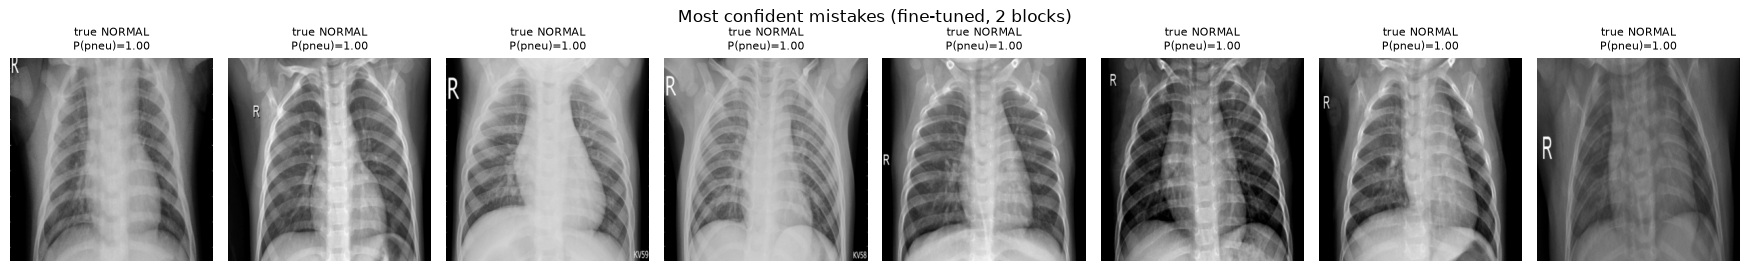

In [10]:
# Failure analysis: test images the best model still gets wrong (seed 0, 2 blocks)
p = PROBS[2]; yt = y_test.numpy(); wrong = np.where((p >= 0.5) != yt)[0]
wrong = wrong[np.argsort(-np.abs(p[wrong] - 0.5))][:8]          # most confident mistakes first
fig, axes = plt.subplots(1, len(wrong), figsize=(2.2 * len(wrong), 2.8))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.imshow(img_test[i, 0], cmap="gray"); ax.axis("off")
    ax.set_title(f"true {CLASSES[yt[i]]}\nP(pneu)={p[i]:.2f}", fontsize=8)
plt.suptitle("Most confident mistakes (fine-tuned, 2 blocks)"); plt.tight_layout()
plt.savefig("results/failures_finetuned.png", dpi=150); plt.show()

## 7. Conclusion
The printed check in Section 6 shows whether each part of our prediction held. **Compare train accuracy with test accuracy:** if the fine-tuned models are near 100 % on training data but gain little on the test set, the extra capacity is mostly fitting this hospital's training images (overfitting / train-test shift). That was the risk we named in the hypothesis.

**Limitations:** single hospital and a single fixed test set (624 images); few seeds; the whole-network row uses a smaller budget; threshold fixed at 0.5. *Research exercise only; no clinical claims.*